# Indian Railways Service Network: EDA and findings

**Question:** where is the passenger network slow, short on AC, or overloaded, and what should a planner look at first?

This notebook walks through the analysis behind the dashboard. It reads only the cleaned CSVs in `data/` (made by `scripts/clean.py`), so it runs without downloading the raw data.

Data: [datameet/railways](https://github.com/datameet/railways) timetable (CC0). It shows service **supply** (what is scheduled), not ridership or demand.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

trains = pd.read_csv("../data/trains_clean.csv", dtype={"number": str})
stations = pd.read_csv("../data/station_traffic.csv")
check = pd.read_csv("../data/speed_halts_check.csv")
print(f"{len(trains):,} train services | {len(stations):,} stations")
trains[["number","name","category","zone","distance","avg_speed_kmph","halts_per_100km","has_ac"]].head()

5,147 train services | 8,486 stations


,number,name,category,zone,distance,avg_speed_kmph,halts_per_100km,has_ac
0,04601,Jammu Tawi Udhampur Special,Passenger & Suburban,NR,53.0,33.5,5.66,0
1,04602,Udhampur Jammutawi DMU,Passenger & Suburban,NR,53.0,28.9,11.32,0
2,04603,JAT Udahmpur DMU,Passenger & Suburban,NR,53.0,33.5,11.32,0
3,04604,Udhampur Jammutawi DMU,Passenger & Suburban,NR,53.0,35.3,5.66,0
4,04728,Mumbai BandraT-Bikaner SF Special,Express & Superfast,NWR,1212.0,55.3,2.31,1


## 1. Data quality snapshot

In [2]:
pd.DataFrame({
    "missing": trains.isna().sum(),
    "unique": trains.nunique(),
}).query("missing > 0 or unique < 20").T

,type,type_name,category,zone,dep_slot,band,has_ac,first_ac,second_ac,third_ac,sleeper,chair_car,first_class
missing,0,0,0,0,0,0,0,0,0,0,0,0,0
unique,16,15,4,18,5,5,2,2,2,2,2,2,2


In [3]:
print(trains[["distance","duration_min","avg_speed_kmph","halts","halts_per_100km"]].describe().round(1))

       distance  duration_min  avg_speed_kmph   halts  halts_per_100km
count    5147.0        5147.0          5147.0  5147.0           5147.0
mean      547.3         677.3            41.6    20.1             12.0
std       697.5         760.6            12.8    14.6             15.4
min         2.0          10.0             8.6     1.0              0.0
25%        91.0         160.0            32.0    10.0              2.6
50%       229.0         365.0            40.2    17.0              8.6
75%       695.0         910.0            51.1    25.0             14.6
max      4279.0        5130.0            89.5   110.0            150.0


Cleaning rules (counts in `data/cleaning_log.txt`, every excluded train with its reason in `data/excluded_trains.csv`): 42 trains without a valid distance or duration, 9 with an impossible speed (including 6 Matheran toy-train timetables listed at 126 km and 58-80 km/h) and 10 with no usable stop times were excluded. Missing railway zones were filled from the origin station, return train or destination station; 80 trains stay `Unknown` and are left out of zone rankings.

In [4]:
excluded = pd.read_csv("../data/excluded_trains.csv", dtype={"number": str})
excluded.reason.value_counts().rename("trains").to_frame()

,trains
reason,
missing or zero distance / duration,42
"no usable stop times (arrival = departure at every stop, even origin and terminus)",10
average speed above the cap for its category,9


## 2. Passenger services are most of the network and the slowest

,services,avg_speed,halts_per_100km,share_%
category,,,,
Heritage / Toy,7,10.6,69.7,0.1
Passenger & Suburban,2861,33.3,19.2,55.6
Express & Superfast,2018,50.4,3.1,39.2
Premium / Fast-track,261,65.4,1.2,5.1


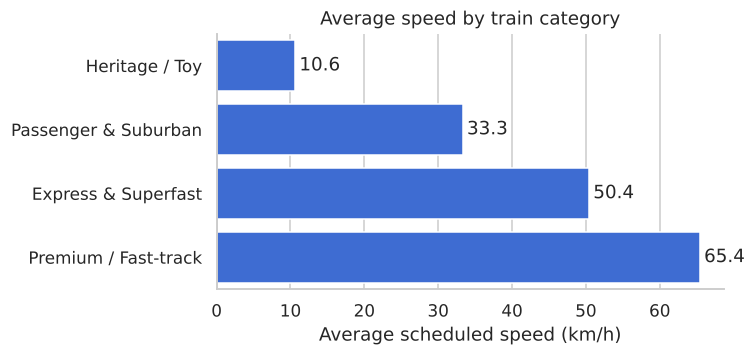

In [5]:
cat = (trains.groupby("category")
       .agg(services=("number","count"), avg_speed=("avg_speed_kmph","mean"), halts_per_100km=("halts_per_100km","mean"))
       .sort_values("avg_speed").round(1))
cat["share_%"] = (100*cat.services/cat.services.sum()).round(1)
display(cat)

fig, ax = plt.subplots(figsize=(7,3.4))
sns.barplot(data=cat.reset_index(), y="category", x="avg_speed", color="#2563eb", ax=ax)
for i,v in enumerate(cat.avg_speed): ax.text(v+0.6, i, f"{v}", va="center")
ax.set(xlabel="Average scheduled speed (km/h)", ylabel="", title="Average speed by train category")
plt.tight_layout(); plt.show()

## 3. More halts per 100 km, lower speed (and why this is not just arithmetic)

Average speed = distance / total time, and total time includes standing time, so some negative correlation is built in. `scripts/speed_vs_halts.py` re-checks it inside distance bands and with standing time removed ("running speed").

In [6]:
display(check.rename(columns={"r_speed_vs_halts100":"r (avg speed)","r_speed_vs_midhalts100":"r (no origin/terminus)","r_runspeed_vs_halts100":"r (running speed)"}).set_index("group"))

,n,r (avg speed),r (no origin/terminus),r (running speed)
group,,,,
ALL,5143,-0.51,-0.47,-0.37
<100 km,1427,-0.21,-0.14,0.19
100-300 km,1441,-0.42,-0.42,-0.31
300-700 km,995,-0.76,-0.76,-0.72
700-1500 km,639,-0.67,-0.67,-0.62
1500+ km,641,-0.66,-0.66,-0.56


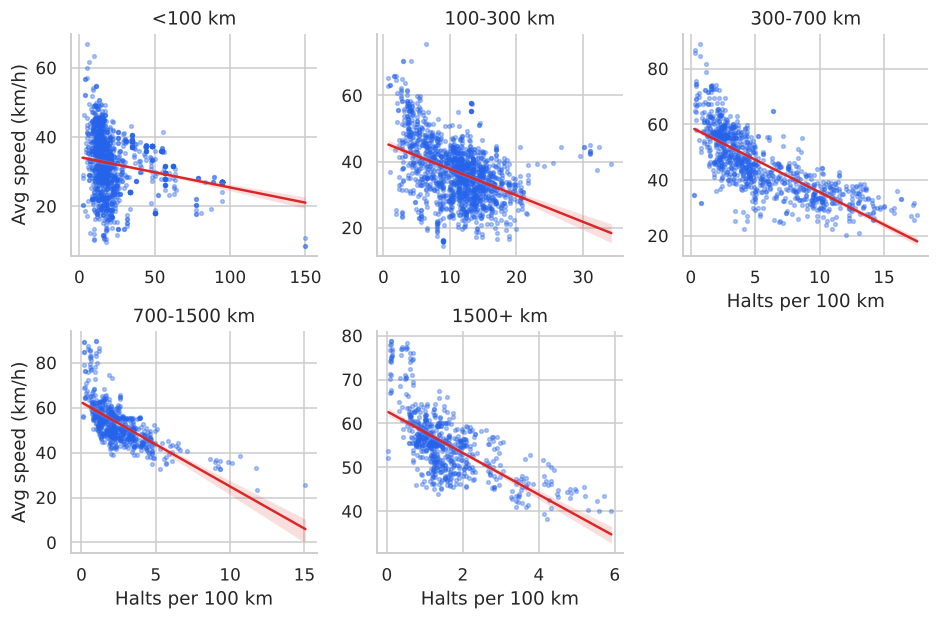

In [7]:
order = ["<100 km","100-300 km","300-700 km","700-1500 km","1500+ km"]
g = sns.FacetGrid(trains, col="band", col_order=order, col_wrap=3, height=2.9, sharex=False, sharey=False)
g.map_dataframe(sns.regplot, x="halts_per_100km", y="avg_speed_kmph", scatter_kws={"s":6,"alpha":.35,"color":"#2563eb"}, line_kws={"color":"#dc2626","lw":1.6})
g.set_axis_labels("Halts per 100 km","Avg speed (km/h)"); g.set_titles("{col_name}")
plt.tight_layout(); plt.show()

Inside each distance band from 100 km up the relationship stays clearly negative even with standing time removed (r from -0.31 to -0.72). Under 100 km it disappears (r = +0.19). This is an **association across trains**, not proof that cutting a stop on one train gives a fixed gain.

## 4. Which zones are slowest?

,services,avg_speed,passenger_share
zone,,,
SECR,142,32.9,75.4
ECR,289,33.1,67.8
NER,386,36.0,67.9
NCR,137,38.3,70.1
NFR,224,38.9,45.1


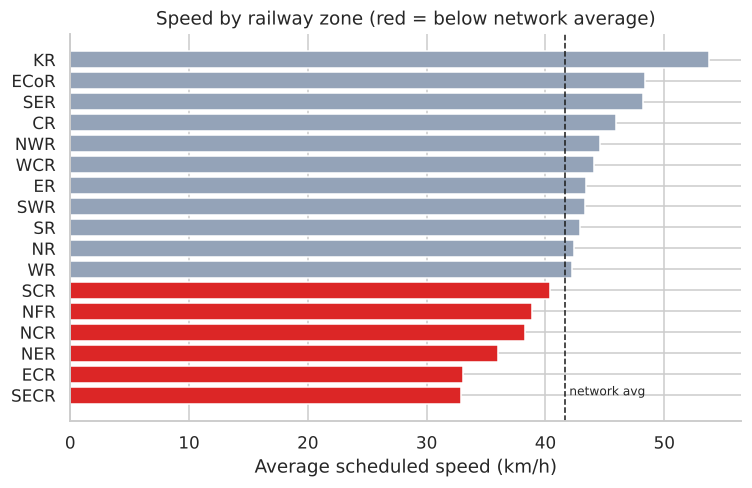

In [8]:
zone = (trains[trains.zone!="Unknown"].groupby("zone")
        .agg(services=("number","count"), avg_speed=("avg_speed_kmph","mean"),
             passenger_share=("category", lambda s:(s=="Passenger & Suburban").mean()*100))
        .round(1).sort_values("avg_speed"))
display(zone.head(5))

fig, ax = plt.subplots(figsize=(7,4.6))
colors = np.where(zone.avg_speed < trains.avg_speed_kmph.mean(), "#dc2626", "#94a3b8")
ax.barh(zone.index, zone.avg_speed, color=colors)
ax.axvline(trains.avg_speed_kmph.mean(), color="k", ls="--", lw=1); ax.text(trains.avg_speed_kmph.mean()+.4, 0, "network avg", fontsize=8)
ax.set(xlabel="Average scheduled speed (km/h)", title="Speed by railway zone (red = below network average)")
plt.tight_layout(); plt.show()

## 5. AC availability gap by distance

,services,non_ac,ac_share_%
band,,,
<100 km,1431,1412,1.3
100-300 km,1441,1244,13.7
300-700 km,995,375,62.3
700-1500 km,639,29,95.5
1500+ km,641,23,96.4


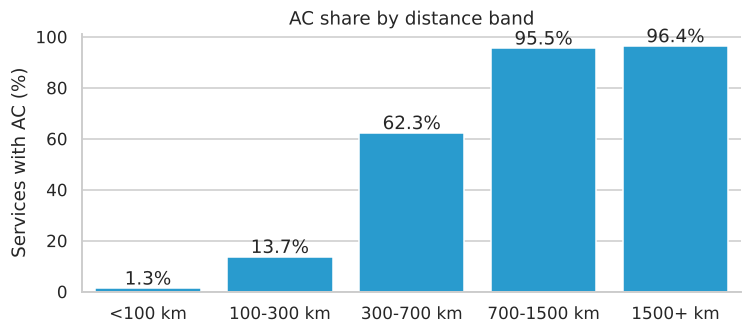

In [9]:
ac = trains.groupby("band", observed=True).agg(services=("number","count"), ac_share=("has_ac","mean")).reindex(order)
ac["ac_share_%"] = (ac.ac_share*100).round(1); ac["non_ac"] = (ac.services*(1-ac.ac_share)).round().astype(int)
display(ac[["services","non_ac","ac_share_%"]])
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(x=ac.index, y=ac["ac_share_%"], color="#0ea5e9", ax=ax)
ax.set(xlabel="", ylabel="Services with AC (%)", title="AC share by distance band")
for i,v in enumerate(ac["ac_share_%"]): ax.text(i, v+1.5, f"{v}%", ha="center")
plt.tight_layout(); plt.show()

The 300-700 km band is the gap: 375 of 995 services (38%) have no AC, while over 700 km about 95-96% do. *AC means any of 1A, 2A, 3A or AC chair car.*

## 6. Hub concentration

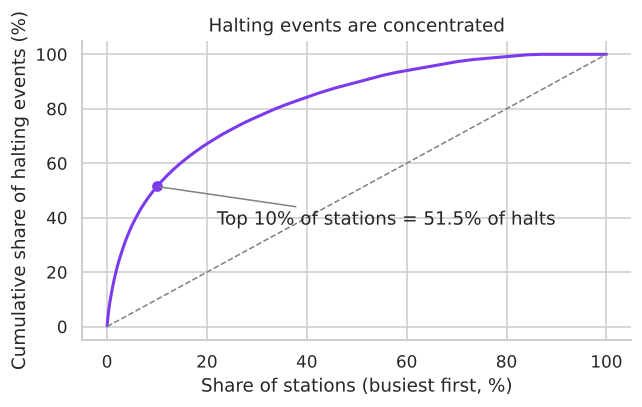

  station_name  trains_halting  trains_passing
Kanpur Central             286              26
     Howrah Jn             283               0
 Vijayawada Jn             257               5
   Vadodara Jn             242              12
     Itarsi Jn             238              53

30.3% of stations have 3 or fewer halting services


In [10]:
s = stations.sort_values("trains_halting", ascending=False).reset_index(drop=True)
cum = s.trains_halting.cumsum()/s.trains_halting.sum()*100
x = (np.arange(1,len(s)+1)/len(s))*100
top10 = cum.iloc[int(round(len(s)*0.10))-1]
fig, ax = plt.subplots(figsize=(6,3.8))
ax.plot(x, cum, color="#7c3aed", lw=2); ax.plot([0,100],[0,100], ls="--", color="grey", lw=1)
ax.scatter([10],[top10], color="#7c3aed", zorder=3); ax.annotate(f"Top 10% of stations = {top10:.1f}% of halts", (10,top10), (22,top10-14), arrowprops=dict(arrowstyle="-", color="grey"))
ax.set(xlabel="Share of stations (busiest first, %)", ylabel="Cumulative share of halting events (%)", title="Halting events are concentrated")
plt.tight_layout(); plt.show()
print(s.head(5)[["station_name","trains_halting","trains_passing"]].to_string(index=False))
print(f"\n{(s.trains_halting<=3).mean()*100:.1f}% of stations have 3 or fewer halting services")

## 7. Departure times

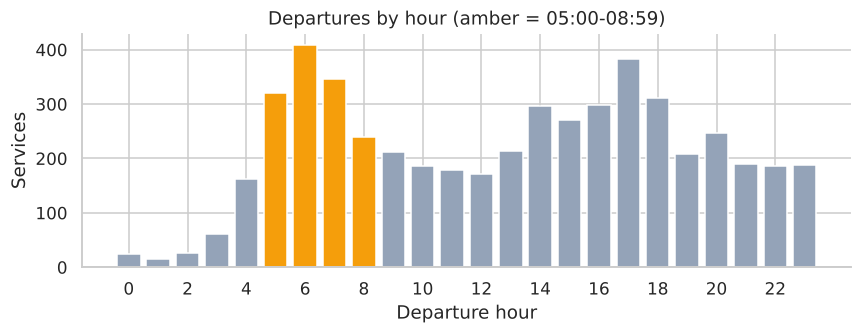

05:00-08:59: 25.6% of departures | 00:00-03:59: 2.5%


In [11]:
h = trains.dep_hour.value_counts().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(8,3.2))
ax.bar(h.index, h.values, color=np.where(h.index.isin(range(5,9)), "#f59e0b", "#94a3b8"))
ax.set(xlabel="Departure hour", ylabel="Services", title="Departures by hour (amber = 05:00-08:59)", xticks=range(0,24,2))
plt.tight_layout(); plt.show()
print(f"05:00-08:59: {trains.dep_hour.between(5,8).mean()*100:.1f}% of departures | 00:00-03:59: {trains.dep_hour.between(0,3).mean()*100:.1f}%")

## 8. What a planner would do first

1. **Passenger & suburban stoppage patterns** in SECR, ECR, NER (slowest zones at 32.9, 33.1, 36.0 km/h, 68-75% passenger share).
2. **AC coaches on 300-700 km non-AC corridors**, starting with NER, NWR, WCR (lowest AC share among zones with at least 20 services in the band: 31%, 39%, 41%).
3. **Hub capacity checks** at the busiest stations (Kanpur Central, Howrah Jn), and stoppage review at the many stations with 3 or fewer halting services (30.3%).
4. **Test the midday window** for new or extra services to ease the 05:00-08:59 peak. This is the weakest of the four: midday holds 3.5% of departures per hour against a 4.2% average, and departure times are origin times, not station load.

### Limits
- Timetable supply only: no ridership, revenue, running days or track capacity.
- The community-collected snapshot looks several years old.
- `halts` counts a stop where arrival and departure differ and includes origin and terminus (+2 per train). Trains whose timetable has no usable stop times were excluded.
- Hyderabad MMTS, Delhi and Kolkata suburban types are counted as Passenger & Suburban; `Heritage / Toy` holds only the 7 toy trains that passed the speed check.